In [1]:
import sys
import matplotlib
import numpy
import pandas
import sklearn

print(
    sys.version.split()[0],
    numpy.__version__,
    pandas.__version__,
    sklearn.__version__,
    matplotlib.__version__)


3.13.0 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2305

data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]

X = data[feature_names].to_numpy()
y = data["spam"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=SEED
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print(
    X.shape,
    round(100 * y.mean(), 1),
    X_train.shape,
    X_test.shape
)


(4204, 57) 39.9 (3153, 57) (1051, 57)


In [3]:
data = pd.read_csv("data/spambase.csv")

print("Shape:", data.shape)
print("Spam percentage:", round(data["spam"].mean() * 100, 1))
print(data.head())

Shape: (4204, 58)
Spam percentage: 39.9
   word_freq_make  word_freq_address  word_freq_all  word_freq_3d  \
0             0.0               0.00           0.00           0.0   
1             0.0               0.00           0.00           0.0   
2             0.0               1.08           0.00           0.0   
3             0.0               0.00           0.00           0.0   
4             0.0               0.00           0.25           0.0   

   word_freq_our  word_freq_over  word_freq_remove  word_freq_internet  \
0           0.00            0.00               0.0                0.00   
1           0.84            0.00               0.0                0.00   
2           0.00            0.00               0.0                0.00   
3           2.04            0.00               0.0                0.00   
4           0.12            0.12               0.0                0.12   

   word_freq_order  word_freq_mail  ...  char_freq_semicolon  char_freq_paren  \
0             0.00 

## Part 1 — Bagging & OOB





In [ ]:
def oob_mask(sample_indices, n_samples):
    """Return a boolean mask for rows absent from the bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

In [ ]:
print(oob_mask([0, 2, 2], 5))
print(oob_mask([], 3))
print(oob_mask(np.array([3, 0]), 4))

[False  True False  True  True]
[ True  True  True]
[False  True  True False]


In [6]:
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    RandomForestClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)

bag = BaggingClassifier(
    DecisionTreeClassifier(),
    n_estimators=100,
    oob_score=True,
    random_state=SEED
)

rf = RandomForestClassifier(
    n_estimators=300,
    oob_score=True,
    random_state=SEED,
    n_jobs=-1
)

lr = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

bag_lr = BaggingClassifier(
    lr,
    n_estimators=50,
    random_state=SEED
)

knn = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

ada = AdaBoostClassifier(
    n_estimators=400,
    random_state=SEED
)

members = [("lr", lr), ("knn", knn), ("tree", tree)]


In [7]:

bag.fit(X_train, y_train)

n = len(X_train)

oob_shares = []

for sample_indices in bag.estimators_samples_:
    mask = oob_mask(sample_indices, n)
    oob_shares.append(mask.mean())

mean_oob = np.mean(oob_shares)
mean_inbag = 1 - mean_oob

theoretical_oob = (1 - 1/n)**n
theoretical_inbag = 1 - theoretical_oob

print(f"Mean OOB share: {mean_oob:.6f}")
print(f"Mean in-bag share: {mean_inbag:.6f}")
print(f"Theoretical OOB share: {theoretical_oob:.6f}")
print(f"Theoretical in-bag share: {theoretical_inbag:.6f}")


Mean OOB share: 0.367431
Mean in-bag share: 0.632569
Theoretical OOB share: 0.367821
Theoretical in-bag share: 0.632179


In [8]:
# Number of training observations
n = len(X_train)

# Two columns: votes for class 0 and class 1
votes = np.zeros((n, 2), dtype=int)

for k, estimator in enumerate(bag.estimators_):
    # Find rows not used by this tree
    mask = oob_mask(bag.estimators_samples_[k], n)
    oob_indices = np.flatnonzero(mask)

    # Predict only OOB observations
    predictions = estimator.predict(X_train[mask])

    # Add votes for the predicted classes
    votes[oob_indices, predictions.astype(int)] += 1

# Choose the class with the most votes
# np.argmax selects class 0 in case of a tie
manual_predictions = np.argmax(votes, axis=1)

# Calculate accuracy
manual_oob_accuracy = np.mean(manual_predictions == y_train)

print(f"Manual OOB accuracy: {manual_oob_accuracy:.6f}")
print(f"Sklearn OOB accuracy: {bag.oob_score_:.6f}")
print(f"Absolute difference: {abs(manual_oob_accuracy - bag.oob_score_):.10f}")
print(f"Rows without OOB votes: {(votes.sum(axis=1) == 0).sum()}")


Manual OOB accuracy: 0.936886
Sklearn OOB accuracy: 0.936886
Absolute difference: 0.0000000000
Rows without OOB votes: 0


In [9]:
from sklearn.model_selection import cross_validate

models = {
    "Decision Tree": tree,
    "Bagging Tree": bag,
    "Random Forest": rf,
    "Logistic Regression": lr,
    "Bagging LR": bag_lr
}

cv_scores = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

    cv_scores[name] = scores

results = pd.DataFrame({
    name: scores for name, scores in cv_scores.items()
}).T

results.columns = [
    "Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"
]

results["Mean"] = results.mean(axis=1)
results["Std"] = results.iloc[:, :5].std(axis=1, ddof=0)

display(results.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
Decision Tree,0.8891,0.9065,0.8970,0.8968,0.8968,0.8972,0.0055
Bagging Tree,0.9319,0.9398,0.9271,0.9238,0.9254,0.9296,0.0058
Random Forest,0.9429,0.9604,0.9334,0.9429,0.9460,0.9451,0.0087
Logistic Regression,0.9461,0.9509,0.9319,0.9333,0.9397,0.9404,0.0073
Bagging LR,0.9398,0.9509,0.9287,0.9349,0.9381,0.9385,0.0073


In [10]:
comparisons = {
    "Bagging - Tree": cv_scores["Bagging Tree"] - cv_scores["Decision Tree"],
    "RF - Tree": cv_scores["Random Forest"] - cv_scores["Decision Tree"],
    "Bagging LR - LR": cv_scores["Bagging LR"] - cv_scores["Logistic Regression"]
}

paired_results = pd.DataFrame(comparisons).T

paired_results.columns = [
    "Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"
]

paired_results["Mean"] = paired_results.iloc[:, :5].mean(axis=1)
paired_results["Std"] = paired_results.iloc[:, :5].std(axis=1, ddof=0)

paired_results["Beyond spread"] = (
    paired_results["Mean"].abs() > paired_results["Std"]
)

display(paired_results.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std,Beyond spread
Bagging - Tree,0.0428,0.0333,0.0301,0.0270,0.0286,0.0323,0.0056,True
RF - Tree,0.0539,0.0539,0.0365,0.0460,0.0492,0.0479,0.0064,True
Bagging LR - LR,-0.0063,0.0000,-0.0032,0.0016,-0.0016,-0.0019,0.0027,False


In [11]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score

# Fit on the full training split
rf.fit(X_train, y_train)

# OOB accuracy
rf_oob = rf.oob_score_

# Cross-validation accuracy
rf_cv_mean = cv_scores["Random Forest"].mean()
rf_cv_std = cv_scores["Random Forest"].std(ddof=0)

# Test accuracy
rf_test_predictions = rf.predict(X_test)
rf_test_accuracy = accuracy_score(y_test, rf_test_predictions)

# Standard error of test accuracy
n_test = len(y_test)

standard_error = np.sqrt(
    rf_test_accuracy * (1 - rf_test_accuracy) / n_test
)

# Agreement between OOB and CV
agreement = abs(rf_oob - rf_cv_mean) <= rf_cv_std

print(f"Random Forest OOB accuracy: {rf_oob:.6f}")
print(f"Random Forest CV accuracy: {rf_cv_mean:.6f} ± {rf_cv_std:.6f}")
print(f"Random Forest test accuracy: {rf_test_accuracy:.6f}")
print(f"Test standard error: {standard_error:.6f}")
print(f"OOB and CV agree: {agreement}")


Random Forest OOB accuracy: 0.949572
Random Forest CV accuracy: 0.945131 ± 0.008718
Random Forest test accuracy: 0.944814
Test standard error: 0.007043
OOB and CV agree: True


### Part 1 — Results and Discussion

The manually calculated out-of-bag accuracy for Bagging was 0.936886, exactly matching scikit-learn's `oob_score_`. No training observations were left without OOB votes.

Bagging improved the Decision Tree's mean cross-validation accuracy from 0.8972 to 0.9296. The paired improvement was 0.0323 ± 0.0056, exceeding the fold spread. Random Forest achieved a higher mean accuracy of 0.9451, with a paired improvement over the single Decision Tree of 0.0479 ± 0.0064. These improvements are consistent with ensemble methods reducing the variance of unstable decision trees.

In contrast, bagging Lo 
 gistic Regression changed mean accuracy from 0.9404 to 0.9385. The paired difference was −0.0019 ± 0.0027, which lies inside the fold spread. Therefore, the results do not establish a winner between Logistic Regression and Bagged Logistic Regression. Bagging has a smaller effect on relatively stable learners such as regularized Logistic Regression.

For Random Forest, the OOB accuracy was 0.949572, the cross-validation accuracy was 0.945131 ± 0.008718, and the test accuracy was 0.944814 with a standard error of 0.007043. The absolute difference between OOB and CV accuracy was approximately 0.004441, smaller than the CV standard deviation. Therefore, the OOB and CV estimates agree according to the assignment's criterion. The test accuracy is also close to both estimates.

## Part 2 — Evaluating the Filter

### 2.1 ROC and Precision–Recall Curves

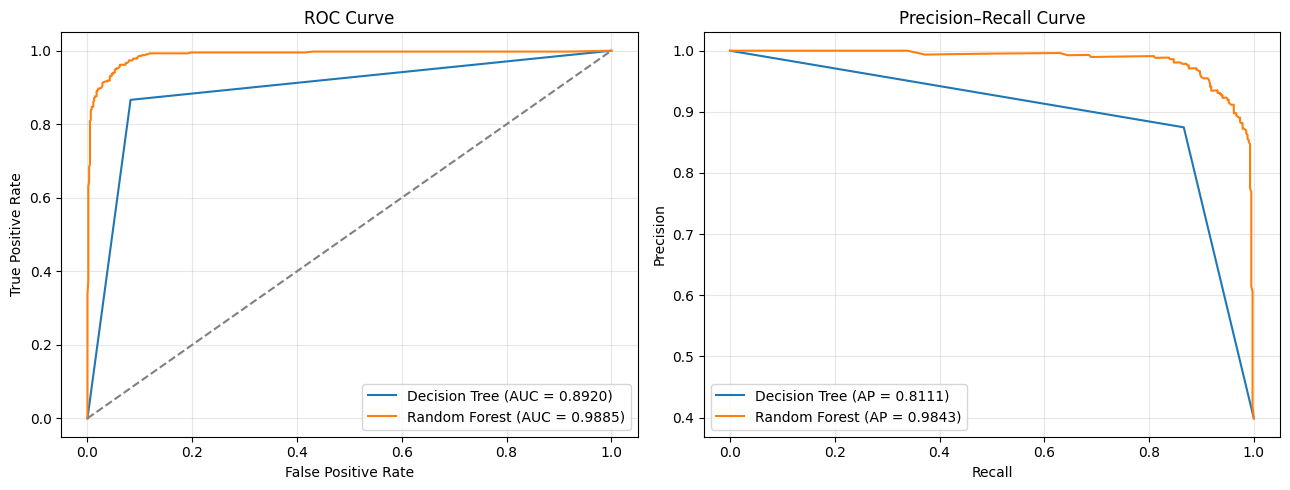

In [13]:
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Train both models only on the training split
tree_eval = clone(tree).fit(X_train, y_train)
rf_eval = clone(rf).fit(X_train, y_train)

# Predict spam probabilities on the test split
tree_probs = tree_eval.predict_proba(X_test)[:, 1]
rf_probs = rf_eval.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, probs in [
    ("Decision Tree", tree_probs),
    ("Random Forest", rf_probs)
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    precision, recall, _ = precision_recall_curve(y_test, probs)

    roc_auc = roc_auc_score(y_test, probs)
    ap = average_precision_score(y_test, probs)

    axes[0].plot(
        fpr, tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

    axes[1].plot(
        recall, precision,
        label=f"{name} (AP = {ap:.4f})"
    )

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Precision–Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [14]:

from sklearn.model_selection import cross_val_predict

# Out-of-fold probabilities from training data only
oof = cross_val_predict(
    rf,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

fpr_oof, tpr_oof, thresholds = roc_curve(
    y_train,
    oof,
    drop_intermediate=False
)

# Only thresholds meeting the FPR requirement
valid = np.where(fpr_oof <= 0.01)[0]

# Highest recall; largest threshold breaks ties
best_recall = np.max(tpr_oof[valid])
candidates = valid[tpr_oof[valid] == best_recall]
best_idx = candidates[np.argmax(thresholds[candidates])]

t = thresholds[best_idx]

print(f"Selected threshold: {t:.8f}")
print(f"Out-of-fold FPR: {fpr_oof[best_idx]:.6f}")
print(f"Out-of-fold Recall: {tpr_oof[best_idx]:.6f}")


Selected threshold: 0.75666667
Out-of-fold FPR: 0.009494
Out-of-fold Recall: 0.789181


In [15]:

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score
)

# Use the threshold selected from training folds
test_pred = (rf_probs >= t).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

test_precision = precision_score(
    y_test, test_pred, zero_division=0
)
test_recall = recall_score(
    y_test, test_pred, zero_division=0
)
test_fpr = fp / (fp + tn)

cm = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual legitimate", "Actual spam"],
    columns=["Predicted legitimate", "Predicted spam"]
)

display(cm)

print(f"Precision: {test_precision:.6f}")
print(f"Recall: {test_recall:.6f}")
print(f"FPR: {test_fpr:.6f}")
print(f"Legitimate emails flagged: {fp} / {fp + tn}")
print(f"1% target met: {test_fpr <= 0.01}")


,Predicted legitimate,Predicted spam
Actual legitimate,629,3
Actual spam,84,335


Precision: 0.991124
Recall: 0.799523
FPR: 0.004747
Legitimate emails flagged: 3 / 632
1% target met: True


Top 5 — Impurity Importance


,Feature,Importance
51,char_freq_exclam,0.118674
52,char_freq_dollar,0.094753
6,word_freq_remove,0.076556
15,word_freq_free,0.073608
54,capital_run_length_average,0.069155


Top 5 — Permutation Importance


,Feature,Importance
6,word_freq_remove,0.021694
24,word_freq_hp,0.015414
51,char_freq_exclam,0.013892
52,char_freq_dollar,0.005899
45,word_freq_edu,0.004662


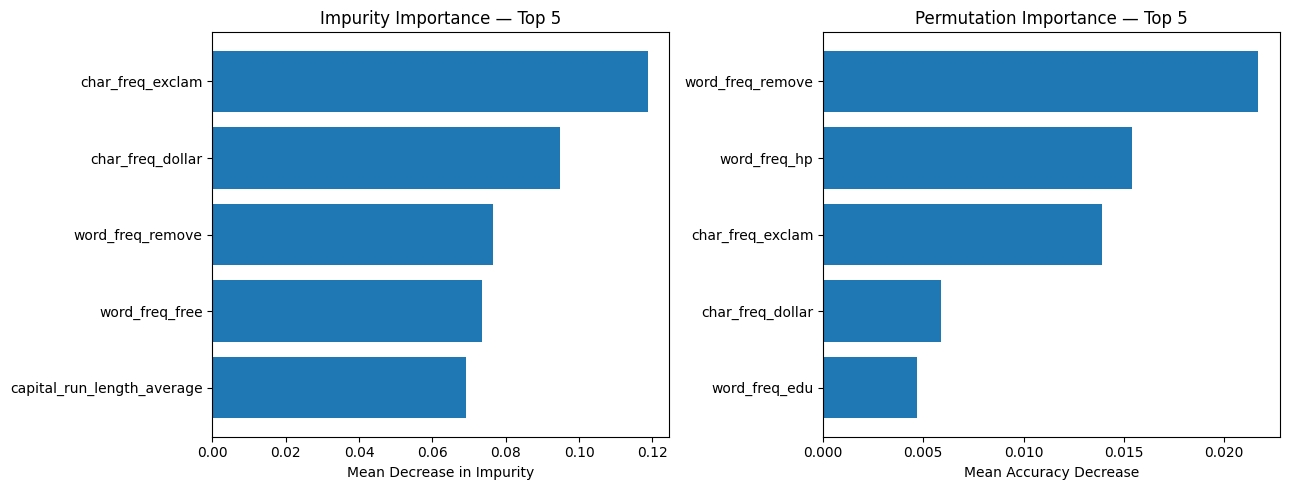

In [16]:

from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_eval,
    X_test,
    y_test,
    n_repeats=10,
    random_state=SEED,
    scoring="accuracy"
)

impurity_table = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_eval.feature_importances_
}).sort_values("Importance", ascending=False).head(5)

permutation_table = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False).head(5)

print("Top 5 — Impurity Importance")
display(impurity_table)

print("Top 5 — Permutation Importance")
display(permutation_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(
    impurity_table["Feature"][::-1],
    impurity_table["Importance"][::-1]
)
axes[0].set_title("Impurity Importance — Top 5")
axes[0].set_xlabel("Mean Decrease in Impurity")

axes[1].barh(
    permutation_table["Feature"][::-1],
    permutation_table["Importance"][::-1]
)
axes[1].set_title("Permutation Importance — Top 5")
axes[1].set_xlabel("Mean Accuracy Decrease")

plt.tight_layout()
plt.show()


### Part 2 — Results and Discussion

**ROC and Precision–Recall Analysis**

The Random Forest outperformed the Decision Tree on both evaluation curves. The Random Forest achieved a ROC-AUC of 0.9885 and an average precision of 0.9843, compared with 0.8920 and 0.8111 for the Decision Tree. These results indicate that the Random Forest provides better discrimination between spam and legitimate emails.

**Threshold Selection**

The classification threshold was selected using out-of-fold probabilities from the training set only. To satisfy the requirement that no more than 1% of legitimate emails be incorrectly classified as spam, the selected threshold was 0.75666667.

At this threshold, the out-of-fold false-positive rate was 0.009494 (0.9494%), and recall was 0.789181 (78.92%).

**Test Set Evaluation**

The selected threshold was applied once to the held-out test set without further adjustment.

The resulting confusion matrix contained:

- True Negatives: 629
- False Positives: 3
- False Negatives: 84
- True Positives: 335

Test precision was 0.991124 (99.11%), recall was 0.799523 (79.95%), and the false-positive rate was 0.004747 (0.4747%).

Only 3 of 632 legitimate test emails were incorrectly flagged as spam. Therefore, the 1% false-positive-rate requirement was satisfied on the test set.

The relatively conservative threshold prioritizes protecting legitimate emails, although 84 spam emails were not detected.

**Feature Importance Analysis**

The impurity-based importance ranking identified `char_freq_exclam` as the most important feature (0.118674), followed by `char_freq_dollar` (0.094753) and `word_freq_remove` (0.076556).

Permutation importance ranked `word_freq_remove` first (0.021694), followed by `word_freq_hp` (0.015414) and `char_freq_exclam` (0.013892).

The rankings differ because impurity importance measures the contribution of features to reducing impurity during tree construction, whereas permutation importance measures the reduction in predictive accuracy after feature values are shuffled.

For example, `char_freq_exclam` ranks first by impurity importance but third by permutation importance. Its contribution to tree splits does not translate into an equally dominant independent effect on test accuracy. Correlations and interactions among features can also influence the difference between the two measures.

**Conclusion**

The Random Forest achieved strong classification performance while satisfying the strict false-positive-rate constraint on the held-out test data. The selected threshold of 0.75666667 provides high precision while retaining approximately 80% spam recall. These results make Random Forest a promising candidate for the spam-filtering task, subject to comparison with the remaining ensemble methods.

## Part 3 — Voting
### 3.1 Hard Voting From Scratch


In [ ]:

def hard_vote(predictions, weights=None):
    """Return weighted majority-vote labels, breaking ties by smallest label."""
    import numpy as np

    pred = np.asarray(predictions, dtype=int)
    n_models, n_samples = pred.shape

    if weights is None:
        w = np.ones(n_models, dtype=float)
    else:
        w = np.asarray(weights, dtype=float)

    result = np.zeros(n_samples, dtype=int)

    for j in range(n_samples):
        scores = np.zeros(int(pred[:, j].max()) + 1, dtype=float)

        for i in range(n_models):
            scores[pred[i, j]] += w[i]

        result[j] = int(np.argmax(scores))

    return result


In [20]:

print(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]))
print(hard_vote([[0, 1], [1, 0]]))
print(hard_vote([[0, 1], [1, 0]], weights=[1, 2]))
print(hard_vote([[2, 0], [2, 1], [0, 1]]))
print(hard_vote([[1, 0], [0, 1]], weights=[0, 0]))


[0 1 0]
[0 0]
[1 0]
[2 1]
[0 0]


In [21]:

from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
from itertools import combinations

# Train each member separately
fitted_members = {
    name: clone(model).fit(X_train, y_train)
    for name, model in members
}

# Predictions have shape (3, n_test)
member_predictions = np.vstack([
    fitted_members[name].predict(X_test)
    for name, _ in members
])

# Our own hard vote
manual_vote = hard_vote(member_predictions)

# Scikit-learn hard vote
hard_model = VotingClassifier(
    estimators=members,
    voting="hard"
)
hard_model.fit(X_train, y_train)

sklearn_vote = hard_model.predict(X_test)

agreement = np.mean(manual_vote == sklearn_vote)

print(f"Agreement with sklearn: {agreement:.6f}")
print("Prediction matrix shape:", member_predictions.shape)

# Pairwise disagreement
disagreement_rows = []

for i, j in combinations(range(len(members)), 2):
    name_i = members[i][0]
    name_j = members[j][0]

    disagreement = np.mean(
        member_predictions[i] != member_predictions[j]
    )

    disagreement_rows.append({
        "Model A": name_i,
        "Model B": name_j,
        "Disagreement": disagreement
    })

disagreement_table = pd.DataFrame(disagreement_rows)
display(disagreement_table)


Agreement with sklearn: 1.000000
Prediction matrix shape: (3, 1051)


,Model A,Model B,Disagreement
0,lr,knn,0.051380
1,lr,tree,0.098002
2,knn,tree,0.107517


In [22]:

from sklearn.model_selection import cross_validate

hard_voting = VotingClassifier(
    estimators=members,
    voting="hard"
)

soft_voting = VotingClassifier(
    estimators=members,
    voting="soft"
)

voting_models = {
    "lr": lr,
    "knn": knn,
    "tree": tree,
    "hard": hard_voting,
    "soft": soft_voting
}

voting_scores = {}

for name, model in voting_models.items():
    voting_scores[name] = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )["test_score"]

voting_table = pd.DataFrame(voting_scores).T

voting_table.columns = [
    "Fold 1", "Fold 2", "Fold 3",
    "Fold 4", "Fold 5"
]

voting_table["Mean"] = voting_table.iloc[:, :5].mean(axis=1)
voting_table["Std"] = voting_table.iloc[:, :5].std(axis=1, ddof=0)

display(voting_table.round(4))


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
lr,0.9461,0.9509,0.9319,0.9333,0.9397,0.9404,0.0073
knn,0.9160,0.9176,0.9287,0.9190,0.9063,0.9175,0.0071
tree,0.8891,0.9065,0.8970,0.8968,0.8968,0.8972,0.0055
hard,0.9429,0.9556,0.9366,0.9365,0.9381,0.9420,0.0072
soft,0.9366,0.9477,0.9350,0.9317,0.9365,0.9375,0.0054


In [23]:

member_names = ["lr", "knn", "tree"]

best_member = max(
    member_names,
    key=lambda name: voting_scores[name].mean()
)

print("Best member:", best_member)
print(
    "Best member CV accuracy:",
    voting_scores[best_member].mean()
)

paired_voting = {}

for method in ["hard", "soft"]:
    differences = (
        voting_scores[method] - voting_scores[best_member]
    )

    mean_diff = differences.mean()
    std_diff = differences.std(ddof=0)

    paired_voting[method] = {
        **{
            f"Fold {i+1}": value
            for i, value in enumerate(differences)
        },
        "Mean": mean_diff,
        "Std": std_diff,
        "Inside fold spread": abs(mean_diff) <= std_diff
    }

    print(f"\n{method.upper()} vs {best_member}")
    print("Paired differences:", np.round(differences, 6))
    print(f"Mean: {mean_diff:.6f}")
    print(f"Std: {std_diff:.6f}")

    if abs(mean_diff) <= std_diff:
        print("No clear winner: inside fold spread")
    elif mean_diff > 0:
        print(f"{method} outperforms {best_member}")
    else:
        print(f"{best_member} outperforms {method}")

display(pd.DataFrame(paired_voting).T.round(6))


Best member: lr
Best member CV accuracy: 0.9403717958393077

HARD vs lr
Paired differences: [-0.00317   0.004754  0.004754  0.003175 -0.001587]
Mean: 0.001585
Std: 0.003325
No clear winner: inside fold spread

SOFT vs lr
Paired differences: [-0.009509 -0.00317   0.00317  -0.001587 -0.003175]
Mean: -0.002854
Std: 0.004059
No clear winner: inside fold spread


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std,Inside fold spread
hard,-0.00317,0.004754,0.004754,0.003175,-0.001587,0.001585,0.003325,True
soft,-0.009509,-0.00317,0.00317,-0.001587,-0.003175,-0.002854,0.004059,True


### Part 3 — Results and Discussion

**Hard Voting Implementation**

The custom `hard_vote` implementation achieved an agreement of 1.000000 (100%) with scikit-learn's `VotingClassifier(voting="hard")` on all 1,051 test observations. This confirms that the implementation reproduces the required majority-voting behavior for the three ensemble members.

**Pairwise Disagreement**

The disagreement rates were 0.051380 for Logistic Regression versus KNN, 0.098002 for Logistic Regression versus Decision Tree, and 0.107517 for KNN versus Decision Tree.

The largest disagreement was observed between KNN and Decision Tree (10.75%), suggesting that these classifiers make different predictions on a substantial subset of emails. However, prediction diversity alone does not guarantee an improvement in ensemble accuracy.

**Cross-Validation Results**

Logistic Regression was the best individual member, with a mean five-fold cross-validation accuracy of 0.940372 (94.04%). Hard Voting achieved 0.941957 (94.20%), while Soft Voting achieved approximately 0.937518 (93.75%).

**Paired Fold Comparison**

For Hard Voting versus Logistic Regression, the mean paired difference was +0.001585 with a standard deviation of 0.003325. Since the absolute mean difference is smaller than the standard deviation, the improvement lies inside the fold spread.

For Soft Voting versus Logistic Regression, the mean paired difference was −0.002854 with a standard deviation of 0.004059. This difference also lies inside the fold spread.

Therefore, neither Hard Voting nor Soft Voting can be declared superior or inferior to the best individual member under the assignment's comparison rule.

**Conclusion**

Combining different classifiers did not produce a clearly distinguishable improvement over Logistic Regression. Although Hard Voting achieved a slightly higher mean accuracy, the difference was smaller than the observed fold-to-fold variation.

## Part 4 — Stacking
### 4.1 Out-of-Fold Stacking

In [ ]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import accuracy_score

# Generate out-of-fold probabilities for each member
oof_columns = []

for name, model in members:
    probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba"
    )[:, 1]

    oof_columns.append(probabilities)

# Three columns: LR, KNN, Tree
X_meta_train = np.column_stack(oof_columns)

print("Meta-training shape:", X_meta_train.shape)

# Fit the meta-learner
meta_model = LogisticRegression()
meta_model.fit(X_meta_train, y_train)

# Fit base models on the full training split
fitted_base = [
    clone(model).fit(X_train, y_train)
    for name, model in members
]

X_meta_test = np.column_stack([
    model.predict_proba(X_test)[:, 1]
    for model in fitted_base
])

manual_stack_predictions = meta_model.predict(X_meta_test)
manual_stack_accuracy = accuracy_score(
    y_test, manual_stack_predictions
)

print("Manual stacking accuracy:", manual_stack_accuracy)
